# PatientWatch: Smart Healthcare Patient Deterioration Monitoring
## Unit 4 · Project 3 · Reproducible research notebook
**Synthetic data only. Educational prototype, not a medical device or clinical decision tool.**

Workflow: dataset → preprocessing → sequence construction → model formulation → algorithms → inference → evaluation → visualization → interpretation.

No MIMIC-IV credentials, patient records or external downloads are required. Run all cells from a cloned repository with `requirements.txt` installed. Ground truth is a simulator regime, not a real clinical outcome.

In [1]:
from pathlib import Path
import os, sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'patientwatch').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from patientwatch.data import generate_cohort, chronological_split, clean_sequences, outcome_labels, FEATURES
from patientwatch.inference import forward_backward, viterbi, emissions, horizon_risk
from patientwatch.pipeline import run_pipeline
SEED = 42
plt.rcParams.update({'figure.figsize': (10, 3.5), 'axes.spines.top': False, 'axes.spines.right': False})
print('Python:', sys.version.split()[0], '| seed:', SEED)

Python: 3.13.14 | seed: 42


## 1. Synthetic dataset and quality assessment
180 patient-disjoint artificial admissions × 48 hourly observations = 8,640 rows. A stationary three-regime Markov simulator produces correlated sequences of five vital signs with patient-level offsets. It injects 7.5% cell missingness and occasional 999 sensor corruption. Admission spacing is three days, preventing temporal overlap across splits. All identities, dates and outcomes are artificial.

In [2]:
raw = generate_cohort(SEED)
display(raw.head())
print('Shape:', raw.shape, '| patients:', raw.patient_id.nunique())
display(pd.DataFrame({'missing_percent': raw[FEATURES].isna().mean()*100,
                      'sentinel_count': (raw[FEATURES] == 999).sum()}))

,patient_id,timestamp,hour,true_state,heart_rate,spo2,resp_rate,systolic_bp,temperature
0,SYN-001,2025-01-01 00:00:00,0,0,73.710916,97.654228,16.743031,109.493164,36.956398
1,SYN-001,2025-01-01 01:00:00,1,0,78.965185,98.080335,16.272460,110.870079,NaN
2,SYN-001,2025-01-01 02:00:00,2,0,87.807567,97.509953,15.355795,109.807334,36.872104
3,SYN-001,2025-01-01 03:00:00,3,0,64.617667,99.029263,14.926647,118.174806,NaN
4,SYN-001,2025-01-01 04:00:00,4,0,62.615943,97.648743,15.473031,111.206493,36.586945


Shape: (8640, 9) | patients: 180


,missing_percent,sentinel_count
heart_rate,7.372685,29
spo2,7.280093,44
resp_rate,7.407407,38
systolic_bp,7.118056,44
temperature,7.627315,41


## 2. Chronological splitting, causal cleaning and sequence construction
First 60% of admissions train; next 20% validate; final 20% test. A patient belongs to one split only. We invalidate out-of-range values, forward-fill **within each sequence**, and fill leading gaps from training medians. Standardization is fitted on training only. No backward fill, future interpolation or cross-patient carry-over is allowed. HMM sequence lengths reset inference at admission boundaries.

In [3]:
train_raw, val_raw, test_raw = chronological_split(raw)
train, medians = clean_sequences(train_raw)
val, _ = clean_sequences(val_raw, medians)
test, _ = clean_sequences(test_raw, medians)
for name, frame in [('train',train),('validation',val),('test',test)]:
    print(name, frame.patient_id.nunique(), 'admissions;', frame.timestamp.min(), 'to', frame.timestamp.max())
assert train.timestamp.max() < val.timestamp.min() < test.timestamp.min()
assert not set(train.patient_id) & set(test.patient_id)
assert train[FEATURES].notna().all().all()
display(medians.to_frame('train_only_fallback'))

train 108 admissions; 2025-01-01 00:00:00 to 2025-11-19 23:00:00
validation 36 admissions; 2025-11-21 00:00:00 to 2026-03-07 23:00:00
test 36 admissions; 2026-03-09 00:00:00 to 2026-06-23 23:00:00


,train_only_fallback
heart_rate,80.746266
spo2,96.578599
resp_rate,18.348368
systolic_bp,115.776689
temperature,37.054848


## 3. Model formulation and maximum likelihood
Let $z_t\in\{0,1,2\}$ be an unobserved regime and $x_t\in\mathbb{R}^5$ standardized vital signs.

$$P(z_{0:T},x_{0:T})=\pi_{z_0}\prod_{t=1}^T A_{z_{t-1},z_t}\prod_{t=0}^T\mathcal{N}(x_t;\mu_{z_t},\mathrm{diag}(\sigma^2_{z_t})).$$

Baum–Welch EM in `hmmlearn` maximizes training likelihood. Three seed-fixed restarts are compared using **training likelihood only**. State count is fixed at three before evaluation. Learned means are ranked by standardized HR − SpO₂ + RR − SBP + temperature. The simulator's true state is **not** used for training or state alignment.

## 4. Core algorithms implemented from scratch
The HMM is a chain factor graph; Forward–Backward is sum-product message passing. Shift log emission rows by their maxima before exponentiation. Normalize each forward row with scale $c_t$. Scale backward messages by $c_{t+1}$; recover likelihood by adding log scales and removed emission shifts.

- Filter: $\alpha_t \propto (\alpha_{t-1} A)\odot b(x_t)$, using only observations up to $t$.
- Backward: $\beta_t=A[b(x_{t+1})\odot\beta_{t+1}]/c_{t+1}$.
- Smooth: $\gamma_t\propto\alpha_t\odot\beta_t$, using the entire sequence.
- Viterbi: log-domain max-product with backpointers; retrospective only.

The following displayed source is the actual from-scratch implementation used in the experiment (no reference-inference calls inside these functions).

In [4]:
print(inspect.getsource(forward_backward))
print(inspect.getsource(viterbi))

def forward_backward(log_emission, start, transition):
    """Return causal alpha, retrospective gamma, log likelihood, scale factors."""
    if len(log_emission) == 0:
        raise ValueError('An observation sequence must not be empty.')
    shift = log_emission.max(axis=1)
    b = np.exp(log_emission - shift[:, None])
    n, k = b.shape
    alpha = np.zeros((n, k))
    scales = np.zeros(n)
    alpha[0] = start * b[0]
    scales[0] = max(alpha[0].sum(), np.finfo(float).tiny)
    alpha[0] /= scales[0]
    for t in range(1, n):
        alpha[t] = (alpha[t - 1] @ transition) * b[t]
        scales[t] = max(alpha[t].sum(), np.finfo(float).tiny)
        alpha[t] /= scales[t]
    beta = np.ones((n, k))
    for t in range(n - 2, -1, -1):
        beta[t] = transition @ (b[t + 1] * beta[t + 1]) / scales[t + 1]
    gamma = alpha * beta
    gamma /= gamma.sum(axis=1, keepdims=True)
    return alpha, gamma, float(np.sum(np.log(scales) + shift)), scales

def viterbi(log_emission, start, transition

## 5. Train and run the full experiment
This cell regenerates every record, fits the scaler and HMM, fits a logistic-regression baseline on current vitals, freezes thresholds on validation, and evaluates test data. It also compares our smoothed posterior and log likelihood to `hmmlearn` on every patient.

In [5]:
result = run_pipeline(seed=SEED, output=ROOT)
print(json.dumps(result['training'], indent=2))
print(json.dumps(result['reference_check'], indent=2))
assert result['reference_check']['max_posterior_error'] < 1e-10
assert result['reference_check']['max_log_likelihood_error'] < 1e-9
display(pd.DataFrame(result['transition'], index=result['state_names'], columns=result['state_names']))
display(pd.DataFrame(result['means'], index=result['state_names'], columns=FEATURES))

{
  "log_likelihood": -20929.454266758017,
  "iterations": 111,
  "converged": true,
  "restarts": 3
}
{
  "max_posterior_error": 5.551115123125783e-16,
  "max_log_likelihood_error": 1.7053025658242404e-13
}


,Stable,Watch,Critical
Stable,0.965030,0.034970,8.294160e-24
Watch,0.062175,0.902492,3.533368e-02
Critical,0.003507,0.043477,9.530162e-01


,heart_rate,spo2,resp_rate,systolic_bp,temperature
Stable,75.015448,97.713541,16.176357,121.029569,36.803485
Watch,94.889013,94.518164,22.878728,107.686667,37.581187
Critical,118.828841,89.493715,30.624562,89.511244,38.466703


## 6. Retrospective early-warning protocol (causal scores)
A synthetic event is the first occurrence of **two consecutive simulator-critical hours**, timestamped at the first hour. Eligible windows are strictly before that event and have an observable six-hour outcome. Negative windows with fewer than six remaining hours are censored. After the first event, all windows are excluded.

The model score is the probability of currently occupying or reaching the learned critical regime within six transitions, computed from **filtered** alpha by making critical absorbing. This is a surrogate for the sustained synthetic event, not its exact probability and not calibrated clinical risk.

Threshold maximizes Youden J on validation only. AUROC, sensitivity and specificity are window-level; lead time is event-level. An event is detected only by an alert in the preceding six hours. Report the median only among detected events. Compare against current-vitals logistic regression with the same data and its own validation threshold. Bootstrap whole test patients (400 replicates), not individual hours.

In [6]:
m = result['metrics']
comparison = pd.DataFrame({
    'Gaussian HMM': {k:m[k] for k in ['auroc','sensitivity','specificity','brier','threshold']},
    'Logistic regression': {k:m['baseline'][k] for k in ['auroc','sensitivity','specificity','brier','threshold']}})
display(comparison)
print('Confusion:', m['confusion'])
print('AUROC 95% patient-bootstrap CI:', m['auroc_ci95'])
print('Detected events:', m['detected_events'], '/', m['total_events'])
print('Median lead hours (detected only):', m['median_lead_hours'])
print('Non-event patients alerted:', m['non_event_patients_alerted'], '/', m['non_event_patients'])

,Gaussian HMM,Logistic regression
auroc,0.792463,0.785820
sensitivity,0.722222,0.722222
specificity,0.842752,0.833743
brier,0.047893,0.048815
threshold,0.059447,0.066457


Confusion: {'tn': 1029, 'fp': 192, 'fn': 20, 'tp': 52}
AUROC 95% patient-bootstrap CI: [0.7075419553369116, 0.8745673552479868]
Detected events: 12 / 12
Median lead hours (detected only): 5.5
Non-event patients alerted: 14 / 24


## 7. Visualization: filtering vs. smoothing, vital trajectory and ROC
Retrospective smoothing may appear to anticipate changes because it uses future evidence. It must never be substituted for filtered scores in an early-warning evaluation. Event markers are simulator ground truth shown for retrospective interpretation.

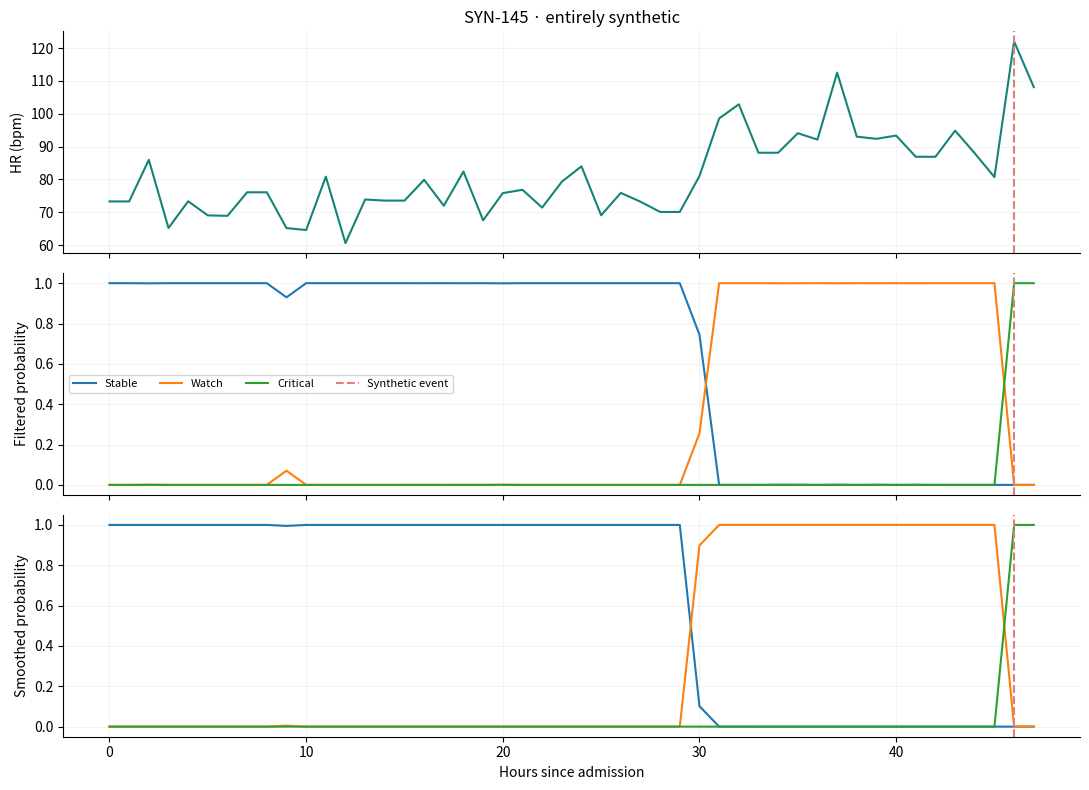

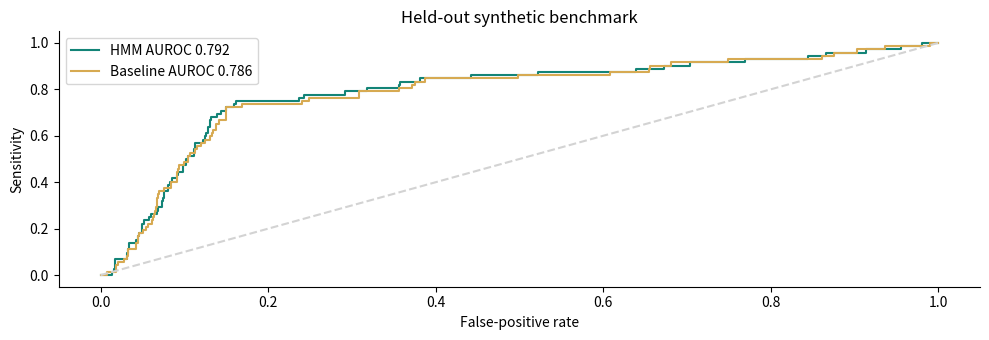

In [7]:
p = next(p for p in result['patients'] if p['split']=='test' and p['event_hour'] is not None and p['event_hour'] > 20)
fig, axes = plt.subplots(3,1,figsize=(11,8),sharex=True)
axes[0].plot(p['hours'],p['vitals']['heart_rate'],color='#138477')
axes[0].set_ylabel('HR (bpm)')
for k,name in enumerate(result['state_names']):
    axes[1].plot(p['hours'],np.array(p['filtered'])[:,k],label=name)
    axes[2].plot(p['hours'],np.array(p['smoothed'])[:,k],label=name)
axes[1].set_ylabel('Filtered probability');axes[2].set_ylabel('Smoothed probability')
for ax in axes:
    ax.axvline(p['event_hour'],color='#db8278',linestyle='--',label='Synthetic event')
    ax.grid(alpha=.15)
axes[1].legend(ncol=4,fontsize=8)
axes[0].set_title(p['id']+' · entirely synthetic')
axes[-1].set_xlabel('Hours since admission');plt.tight_layout();plt.show()
fig,ax=plt.subplots()
r=result['roc']
ax.plot(r['fpr'],r['tpr'],label=f"HMM AUROC {m['auroc']:.3f}",color='#138477')
ax.plot(r['baseline_fpr'],r['baseline_tpr'],label=f"Baseline AUROC {m['baseline']['auroc']:.3f}",color='#d7aa52')
ax.plot([0,1],[0,1],'--',color='lightgray');ax.set(xlabel='False-positive rate',ylabel='Sensitivity',title='Held-out synthetic benchmark')
ax.legend();plt.tight_layout();plt.show()

## 8. Causality check and independent reference comparison
Change future observations: filtered posteriors in the prefix must not change. Compare full-sequence Viterbi with the reference library using the saved learned parameters.

In [8]:
from hmmlearn.hmm import GaussianHMM
params=np.load(ROOT/'artifacts/model.npz')
model=GaussianHMM(n_components=3,covariance_type='diag',implementation='scaling',init_params='')
model.startprob_=params['start'];model.transmat_=params['transition']
model.means_=params['means'];model.covars_=params['variances']
x=(test[test.patient_id==p['id']][FEATURES].to_numpy()-params['scaler_mean'])/params['scaler_scale']
log_b=emissions(x,params['means'],params['variances'])
a,g,ll,_=forward_backward(log_b,params['start'],params['transition'])
changed=log_b.copy();changed[25:]=0
new_a,_,_,_=forward_backward(changed,params['start'],params['transition'])
assert np.allclose(a[:25],new_a[:25])
assert np.array_equal(viterbi(log_b,params['start'],params['transition']),model.predict(x))
print('PASS: causal prefix is invariant; Viterbi path equals reference.')

PASS: causal prefix is invariant; Viterbi path equals reference.


## 9. Interpretation, limitations and next steps
The synthetic HMM gives moderate discrimination, not a perfect early-warning system. Its small AUROC advantage over the non-sequential baseline does not establish statistical superiority. High event recall coexists with substantial false-alert burden. Event sensitivity differs from hourly sensitivity, and lead-time summaries exclude missed events.

The generator is stationary and close to a Gaussian HMM; this favors the model. Missingness is mostly random, not reflective of clinical measurement practice. There are no treatments, demographic subgroups, irregular samples or independent event adjudication. A small test cohort and one seed limit conclusions. Absolute scores are not clinically calibrated.

A real extension requires credentialed MIMIC-IV access, approved data handling, clinically grounded endpoints, temporal/external validation, calibration, subgroup audits, missingness modeling and clinician review. Never deploy this prototype for diagnosis or triage.

## References
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257–286. doi:10.1109/5.18626.
- `hmmlearn` documentation: https://hmmlearn.readthedocs.io/
- `scikit-learn` model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html
- MIMIC-IV access requirements (not used): https://physionet.org/content/mimiciv/

## Demonstration
Run `python app.py`, visit `http://localhost:3000`, explore patient timelines, switch filtering/smoothing, inspect performance and download files. Full experiment source is in `patientwatch/`.